In [1]:
# import pandas as pd

# df_crop_rec_1 = pd.read_csv('data/Crop Recommendation using Soil Properties and Weather Prediction.csv')
# df_crop_rec_2 = pd.read_csv('data/crop_recommendation (1).csv')
# df_crop_rec_3 = pd.read_csv('data/Crop_recommendation (2).csv')
# df_crop_rec_4 = pd.read_csv('data/Crop_recommendation (3).csv')
# df_crop_rec_5 = pd.read_csv('data/Crop_recommendation.csv')

# print(df_crop_rec_1.columns)
# print(df_crop_rec_2.columns)
# print(df_crop_rec_3.columns)
# print(df_crop_rec_4.columns)
# print(df_crop_rec_5.columns)

# print("----")

# print(sum(df_crop_rec_2['N']))
# print(sum(df_crop_rec_3['N']))
# print(sum(df_crop_rec_4['N']))
# print(sum(df_crop_rec_5['N']))

# print("--------")
# print(sum(df_crop_rec_2['temperature']))
# print(sum(df_crop_rec_3['temperature']))
# print(sum(df_crop_rec_4['temperature']))
# print(sum(df_crop_rec_5['temperature']))

In [2]:
import pandas as pd

df_ethiopia = pd.read_csv("data/crop_rec_ethiopia.csv")
df_india = pd.read_csv("data/crop_rec_india.csv")
df_synthetic = pd.read_csv("data/crop_rec_synthetic.csv")

print(f"ethiopia columns: {df_ethiopia.columns}")
print(f"india columns: {df_india.columns}")
print(f"synthetic columns: {df_synthetic.columns}")

ethiopia columns: Index(['Soilcolor', 'Ph', 'K', 'P', 'N', 'Zn', 'S', 'QV2M-W', 'QV2M-Sp',
       'QV2M-Su', 'QV2M-Au', 'T2M_MAX-W', 'T2M_MAX-Sp', 'T2M_MAX-Su',
       'T2M_MAX-Au', 'T2M_MIN-W', 'T2M_MIN-Sp', 'T2M_MIN-Su', 'T2M_MIN-Au',
       'PRECTOTCORR-W', 'PRECTOTCORR-Sp', 'PRECTOTCORR-Su', 'PRECTOTCORR-Au',
       'WD10M', 'GWETTOP', 'CLOUD_AMT', 'WS2M_RANGE', 'PS', 'label'],
      dtype='object')
india columns: Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')
synthetic columns: Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'crop'], dtype='object')


In [3]:
# need to make ethiopia columns match other 2
    # -W = Winter, -Sp = Spring, -Su = Summer, -Au = Autum
    # T2M_MAX = max temperature
    # T2M_MIN = min temperature
    # QV2M = humidity 2 m above ground
    # PRECTOTCORR = corrected rainfall 
df_eth_final = pd.DataFrame(df_ethiopia, columns=["N", "P", "K", 'T2M_MAX-W', 'T2M_MAX-Sp', 'T2M_MAX-Su',
       'T2M_MAX-Au', 'T2M_MIN-W', 'T2M_MIN-Sp', 'T2M_MIN-Su', 'T2M_MIN-Au', 'QV2M-W', 'QV2M-Sp',
       'QV2M-Su', 'QV2M-Au', "Ph", 'PRECTOTCORR-W', 'PRECTOTCORR-Sp', 'PRECTOTCORR-Su', 'PRECTOTCORR-Au', "label"])
#N
# df = df.rename(columns={"N": "n"})
#P
#K
#temperature
df_eth_final["temperature"] = df_eth_final[['T2M_MAX-W', 'T2M_MAX-Sp', 'T2M_MAX-Su',
       'T2M_MAX-Au', 'T2M_MIN-W', 'T2M_MIN-Sp', 'T2M_MIN-Su', 'T2M_MIN-Au']].mean(axis=1)

#humidity
df_eth_final["humidity"] = df_eth_final[['QV2M-W', 'QV2M-Sp', 'QV2M-Su', 'QV2M-Au']].mean(axis=1)

#ph
df_eth_final = df_eth_final.rename(columns={"Ph": "ph"})

#rainfall
df_eth_final["rainfall"] = df_eth_final[['PRECTOTCORR-W', 'PRECTOTCORR-Sp', 'PRECTOTCORR-Su', 'PRECTOTCORR-Au']].mean(axis=1)

#label/crop
df_synthetic = df_synthetic.rename(columns={"crop": "label"})

# drop unnecessary columns
df_eth_final = df_eth_final.drop(columns=['T2M_MAX-W', 'T2M_MAX-Sp', 'T2M_MAX-Su',
       'T2M_MAX-Au', 'T2M_MIN-W', 'T2M_MIN-Sp', 'T2M_MIN-Su', 'T2M_MIN-Au', 'QV2M-W', 
       'QV2M-Sp', 'QV2M-Su', 'QV2M-Au', 'PRECTOTCORR-W', 'PRECTOTCORR-Sp', 'PRECTOTCORR-Su', 'PRECTOTCORR-Au'])

print(f"ETHIOPIA FINAL columns: {df_eth_final.columns}")
print(f"SYNETHETIC FINAL columns: {df_synthetic.columns}")
print(f"INDIA FINAL columns: {df_india.columns}")

df_eth_final.to_csv("data/ethiopia_final.csv", index=False)
df_synthetic.to_csv("data/synthetic_final.csv", index=False)
df_india.to_csv("data/india_final.csv", index=False)

ETHIOPIA FINAL columns: Index(['N', 'P', 'K', 'ph', 'label', 'temperature', 'humidity', 'rainfall'], dtype='object')
SYNETHETIC FINAL columns: Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')
INDIA FINAL columns: Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')


In [4]:
import pandas as pd
ethiopia = pd.read_csv("data/ethiopia_final.csv")
synthetic = pd.read_csv("data/synthetic_final.csv")
india = pd.read_csv("data/india_final.csv")

features = [
    "N", "P", "K",
    "temperature", "humidity", "ph", "rainfall"
]

target = "label"

datasets = {
    "Ethiopia": ethiopia,
    "Synthetic": synthetic,
    "India": india
}

for name, df in datasets.items():
    df.columns = df.columns.str.strip()
    df["label"] = df["label"].astype(str).str.strip().str.lower()

    datasets[name] = df[features + [target]].copy()

    print(f"{name}: {datasets[name].shape}")
    print("Classes:", datasets[name][target].nunique())
    print()


Ethiopia: (3867, 8)
Classes: 12

Synthetic: (1000, 8)
Classes: 7

India: (2200, 8)
Classes: 22



In [5]:
for name, df in datasets.items():
    print(name, sorted(df["label"].unique()))

Ethiopia ['barley', 'bean', 'dagussa', 'fallow', 'maize', 'niger seed', 'pea', 'potato', 'red pepper', 'sorghum', 'teff', 'wheat']
Synthetic ['barley', 'cotton', 'maize', 'rice', 'soybean', 'sugarcane', 'wheat']
India ['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']


In [6]:

import pandas as pd
synth = pd.read_csv("data/synthetic_final.csv")
features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

print(synth.groupby("label")[features].mean().round(2))
print("st deviations")
print(synth.groupby("label")[features].std().round(2))

               N      P       K  temperature  humidity    ph  rainfall
label                                                                 
Barley     71.93  59.60  104.94        27.50     53.93  6.82    174.99
Cotton     68.78  53.44  106.69        27.25     53.47  6.71    171.82
Maize      68.05  63.77   96.69        27.10     53.08  6.85    178.83
Rice       70.42  61.21   97.21        27.34     53.53  6.55    172.13
Soybean    72.33  59.85   97.82        27.55     55.72  6.77    175.15
Sugarcane  67.27  57.36  105.44        27.56     56.46  6.72    176.71
Wheat      72.50  59.81  101.24        28.61     55.68  6.57    174.31
st deviations
               N      P      K  temperature  humidity    ph  rainfall
label                                                                
Barley     40.79  35.28  58.57         6.96     19.42  1.35     74.50
Cotton     39.55  36.49  54.01         6.95     20.07  1.22     71.98
Maize      38.31  31.50  54.45         7.60     20.69  1.27     75.

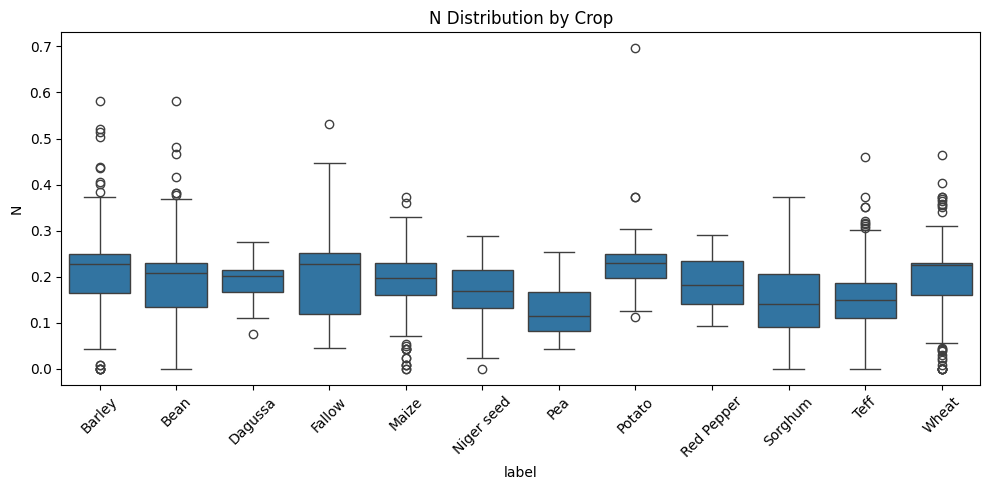

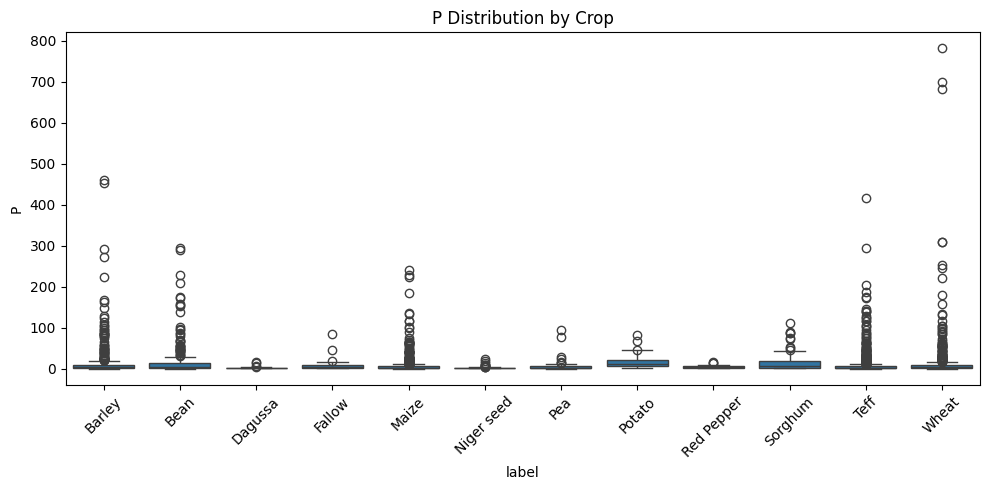

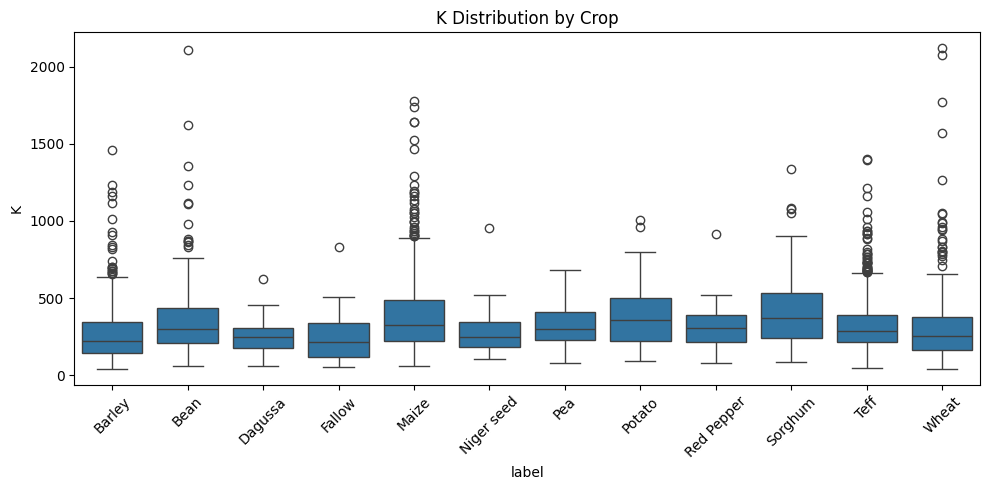

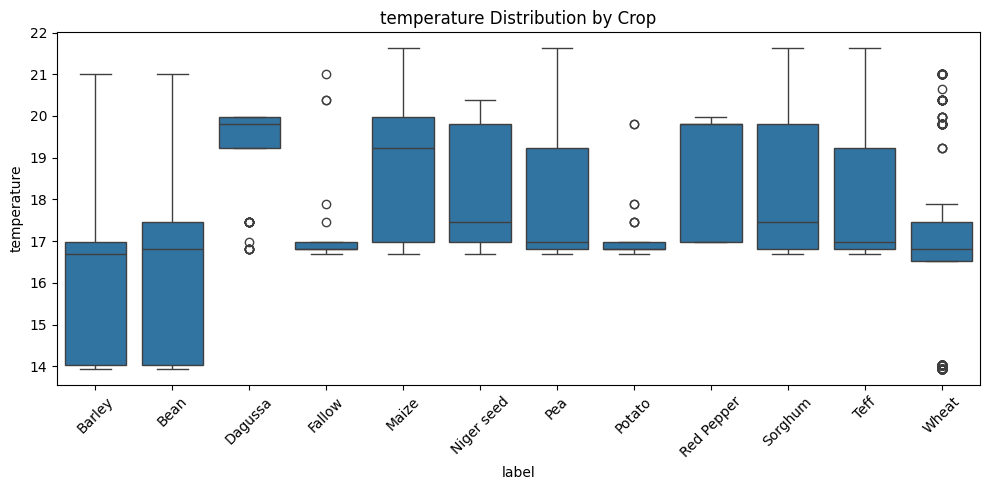

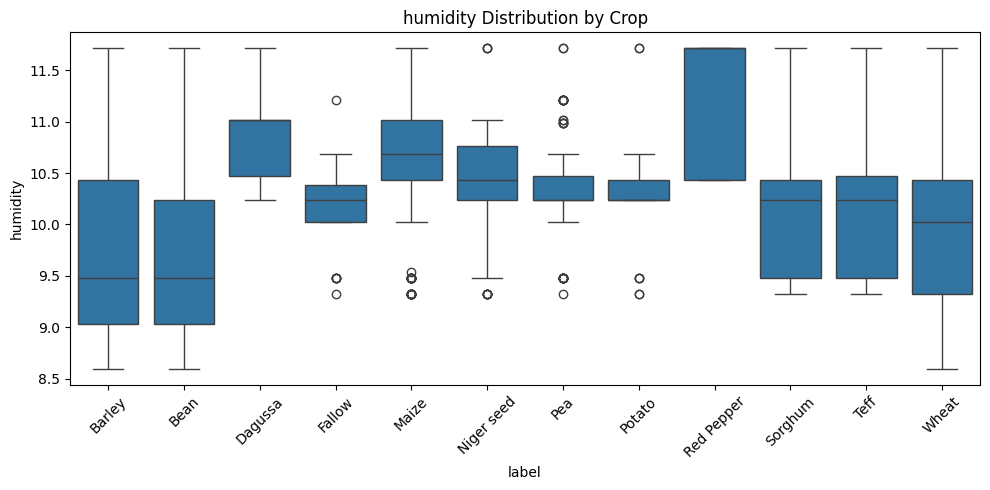

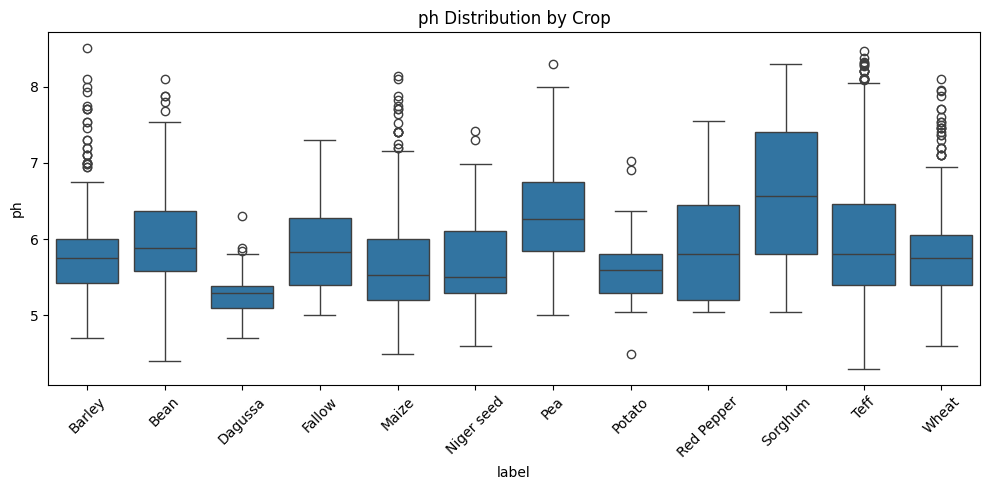

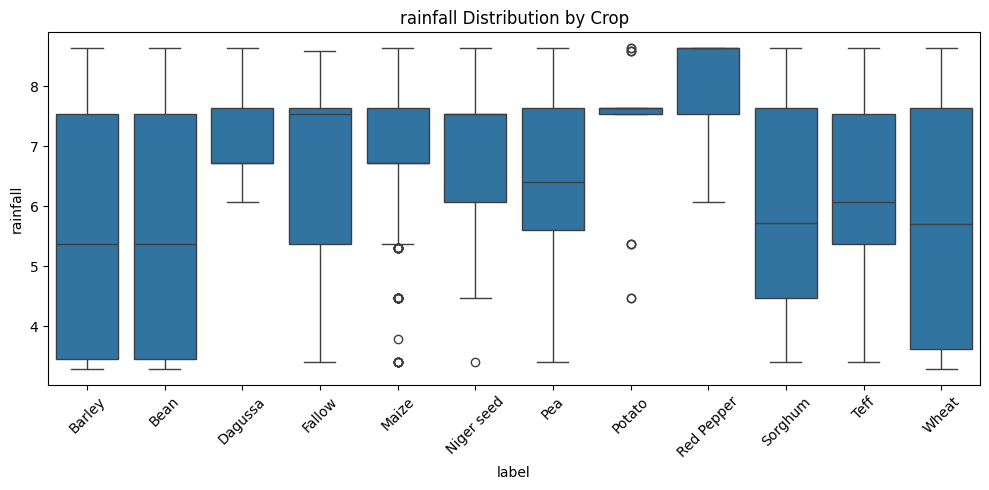

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

eth = pd.read_csv("data/ethiopia_final.csv")
synth = pd.read_csv("data/synthetic_final.csv")
ind = pd.read_csv("data/india_final.csv")
features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
target = "label"
results = []
for feature in features:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=eth, x="label", y=feature)
    plt.title(f"{feature} Distribution by Crop")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
